In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("Bengaluru_House_Data.csv")
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [5]:
df.shape

(13320, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [7]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [8]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

<Axes: xlabel='price', ylabel='Count'>

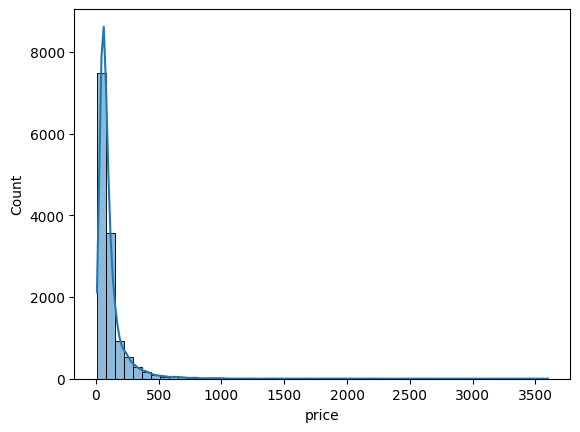

In [9]:
sns.histplot(df['price'], bins = 50 , kde = True)

<Axes: >

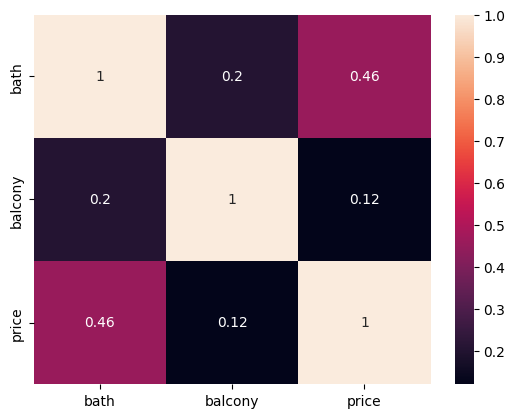

In [10]:
sns.heatmap(df.corr(numeric_only = True),annot = True)

<Axes: xlabel='area_type', ylabel='price'>

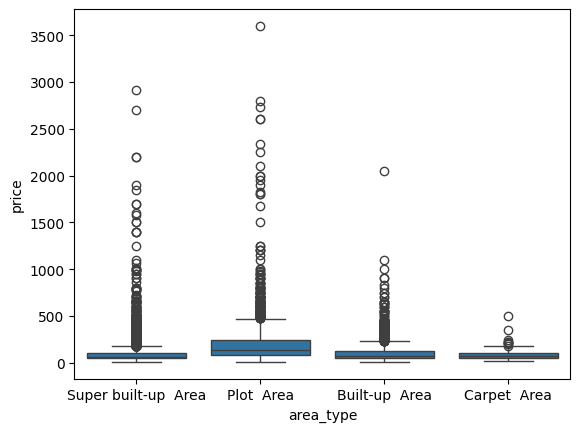

In [11]:
sns.boxplot(data = df, x='area_type' , y = 'price')

<Axes: xlabel='balcony', ylabel='price'>

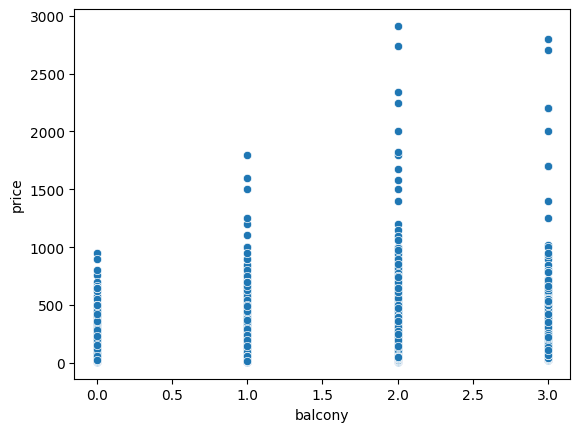

In [12]:
sns.scatterplot(data = df, x='balcony' , y = 'price')

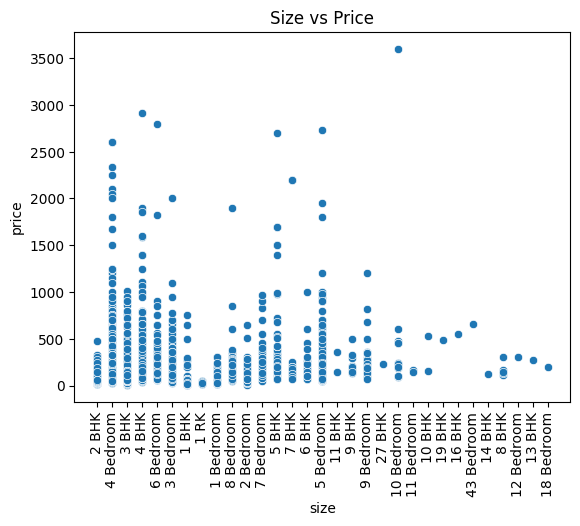

In [13]:
sns.scatterplot(x='size', y='price', data=df)
plt.xticks(rotation=90)
plt.title("Size vs Price")

plt.show()

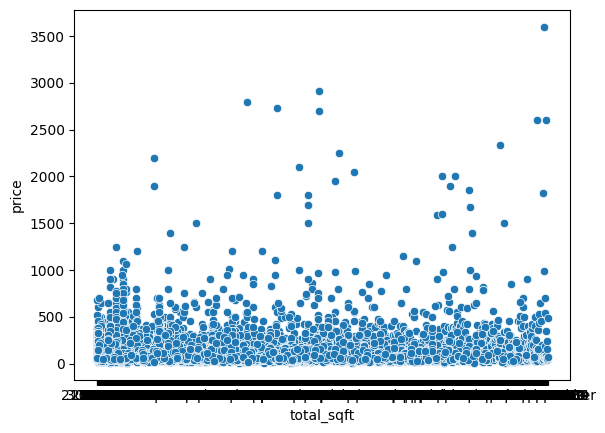

In [14]:
sns.scatterplot(x='total_sqft', y='price', data=df)
plt.show()

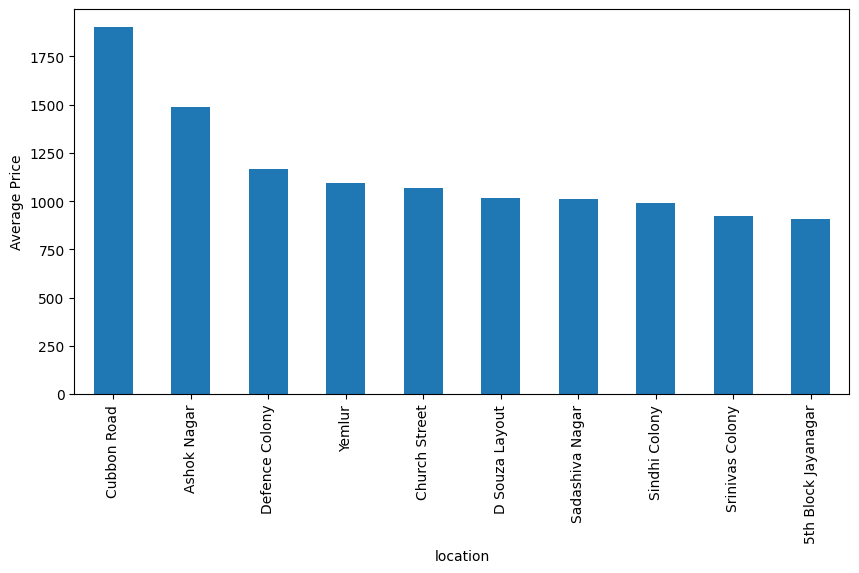

In [15]:
avg_price = df.groupby('location')['price'].mean().sort_values(ascending=False).head(10)

avg_price.plot(kind='bar', figsize=(10,5))
plt.ylabel("Average Price")
plt.show()

In [16]:

df['availability'] = df['availability'].replace('Immediate Possession', 'Ready to Move')
df['is_ready'] = df['availability'].apply(lambda x: 1 if x == 'Ready To Move' else 0)

In [17]:
df.drop(['area_type', 'society', 'balcony', 'availability'], axis=1, inplace=True)


In [18]:
df.dropna(inplace=True)


In [19]:
df.head()

,location,size,total_sqft,bath,price,is_ready
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,0
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,1
2,Uttarahalli,3 BHK,1440,2.0,62.00,1
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,1
4,Kothanur,2 BHK,1200,2.0,51.00,1


In [20]:
df.isnull().sum()

location      0
size          0
total_sqft    0
bath          0
price         0
is_ready      0
dtype: int64

In [21]:
df.shape

(13246, 6)

In [22]:
df['bhk'] = df['size'].apply(lambda x: int(x.split(' ')[0]))
df.head()

,location,size,total_sqft,bath,price,is_ready,bhk
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,0,2
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,1,4
2,Uttarahalli,3 BHK,1440,2.0,62.00,1,3
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,1,3
4,Kothanur,2 BHK,1200,2.0,51.00,1,2


In [23]:
df[df.bhk>20]

,location,size,total_sqft,bath,price,is_ready,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,1,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,1,43


In [24]:
def is_float(x):
    try:
        float(x)
    except:
        return False
    return True
df[~df['total_sqft'].apply(is_float)].head(10)

,location,size,total_sqft,bath,price,is_ready,bhk
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,0,4
122,Hebbal,4 BHK,3067 - 8156,4.0,477.000,0,4
137,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,0,2
165,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,0,2
188,KR Puram,2 BHK,1015 - 1540,2.0,56.800,1,2
410,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1,1
549,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,0,2
648,Arekere,9 Bedroom,4125Perch,9.0,265.000,1,9
661,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,1,2
672,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,0,4


In [25]:
def convert_sqft(x):
    tokens = x.split('-')
    if len(tokens) == 2:
        try:
            return (float(tokens[0]) + float(tokens[1])) / 2
        except:
            return None
    try:
        return float(x)          
    except:
        return None              

df['total_sqft'] = df['total_sqft'].apply(convert_sqft)
df.dropna(inplace=True)
df.head()

,location,size,total_sqft,bath,price,is_ready,bhk
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,0,2
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,1,4
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,1,3
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,1,3
4,Kothanur,2 BHK,1200.0,2.0,51.00,1,2


In [26]:
df.dtypes

location       object
size           object
total_sqft    float64
bath          float64
price         float64
is_ready        int64
bhk             int64
dtype: object

In [27]:
df["price_per_sqft"] = df["price"]*100000/df["total_sqft"]
df.head()

,location,size,total_sqft,bath,price,is_ready,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,0,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,1,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,1,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,1,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,1,2,4250.000000


In [28]:
df['price_per_sqft'].describe()

count    1.320000e+04
mean     7.920759e+03
std      1.067272e+05
min      2.678298e+02
25%      4.267701e+03
50%      5.438331e+03
75%      7.317073e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64

In [29]:
df.location.unique()

array(['Electronic City Phase II', 'Chikka Tirupathi', 'Uttarahalli', ...,
       '12th cross srinivas nagar banshankari 3rd stage',
       'Havanur extension', 'Abshot Layout'], dtype=object)

In [30]:
len(df.location.unique())

1298

In [31]:
df.location = df.location.apply(lambda x : x.strip())
location_stats = df.groupby('location')['location'].agg('count').sort_values(ascending=False)
location_stats


location
Whitefield               533
Sarjapur  Road           392
Electronic City          304
Kanakpura Road           264
Thanisandra              235
                        ... 
1 Giri Nagar               1
Kanakapura Road,           1
Kanakapura main  Road      1
Kannur                     1
whitefiled                 1
Name: location, Length: 1287, dtype: int64

In [32]:
len(location_stats[location_stats<=10])

1047

In [33]:
location_stats_with_less_than_10 = location_stats[location_stats<=10]
location_stats_with_less_than_10

location
Sadashiva Nagar          10
Naganathapura            10
Basapura                 10
Nagadevanahalli          10
Kalkere                  10
                         ..
1 Giri Nagar              1
Kanakapura Road,          1
Kanakapura main  Road     1
Kannur                    1
whitefiled                1
Name: location, Length: 1047, dtype: int64

In [34]:
df.location = df.location.apply(lambda x: 'Other' if x in location_stats_with_less_than_10 else x)
len(df.location.unique())

241

In [35]:
df.head(20)

,location,size,total_sqft,bath,price,is_ready,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,0,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,1,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,1,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,1,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,1,2,4250.000000
5,Whitefield,2 BHK,1170.0,2.0,38.00,1,2,3247.863248
6,Old Airport Road,4 BHK,2732.0,4.0,204.00,0,4,7467.057101
7,Rajaji Nagar,4 BHK,3300.0,4.0,600.00,1,4,18181.818182
8,Marathahalli,3 BHK,1310.0,3.0,63.25,1,3,4828.244275
9,Other,6 Bedroom,1020.0,6.0,370.00,1,6,36274.509804


In [36]:
df[df.total_sqft/df.bhk<300].head()

,location,size,total_sqft,bath,price,is_ready,bhk,price_per_sqft
9,Other,6 Bedroom,1020.0,6.0,370.0,1,6,36274.509804
45,HSR Layout,8 Bedroom,600.0,9.0,200.0,1,8,33333.333333
58,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,1,6,10660.980810
68,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,1,8,6296.296296
70,Other,3 Bedroom,500.0,3.0,100.0,1,3,20000.000000


In [37]:
df.shape

(13200, 8)

In [38]:
outlier_data = df[df.total_sqft/df.bhk<300]
len(outlier_data)

744

In [39]:
df = df[~(df.total_sqft/df.bhk<300)]
df.shape

(12456, 8)

In [40]:
df.price_per_sqft.describe()

count     12456.000000
mean       6308.502826
std        4168.127339
min         267.829813
25%        4210.526316
50%        5294.117647
75%        6916.666667
max      176470.588235
Name: price_per_sqft, dtype: float64

In [41]:
#m = mean, std = standard deviation
#filtering out data beyond standard deviation
#diff area ka diff price range

def remove_pps_outliers(df):
    df_out = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        m = np.mean(subdf.price_per_sqft)
        std = np.std(subdf.price_per_sqft)
        reduced_df = subdf[(subdf.price_per_sqft > (m-std)) & (subdf.price_per_sqft <= (m+std))]
        df_out = pd.concat([df_out, reduced_df], ignore_index = True)
    return df_out;

df = remove_pps_outliers(df)
df.shape

(10242, 8)

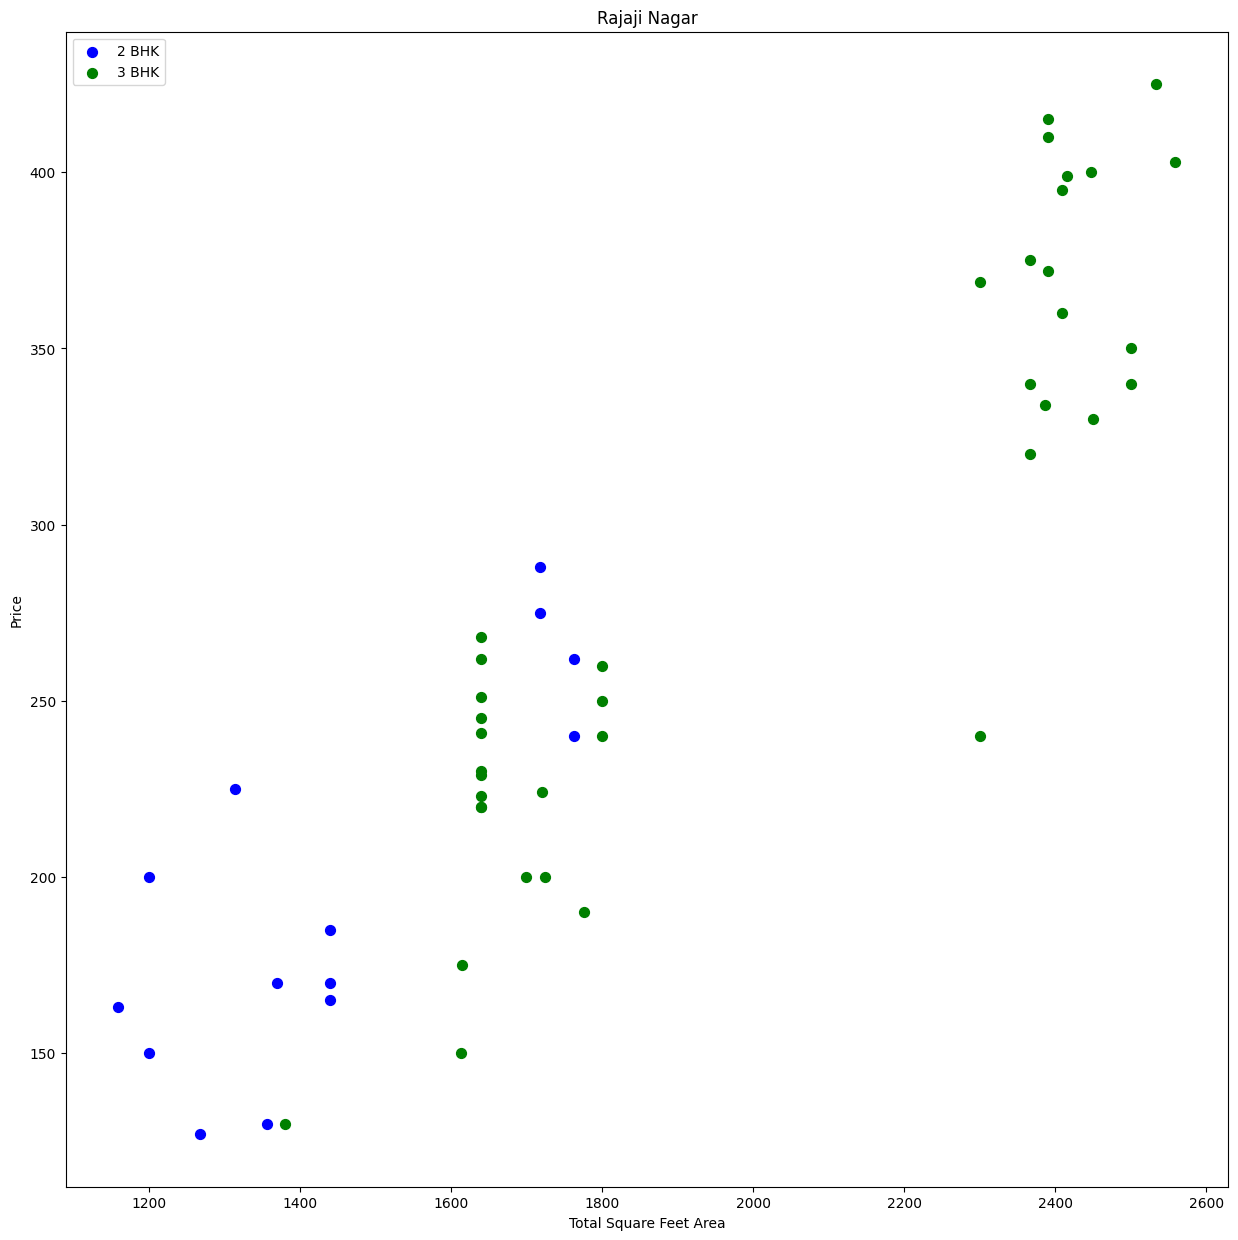

In [42]:
def scatter_plot(df,location):
    bhk2 = df[(df.location == location) & (df.bhk == 2)]
    bhk3 = df[(df.location == location) & (df.bhk == 3)]
    plt.rcParams["figure.figsize"] = (15,15)
    plt.scatter(bhk2.total_sqft, bhk2.price, color='blue', label = '2 BHK', s=50)
    plt.scatter(bhk3.total_sqft, bhk3.price, color='green', label = '3 BHK', s=50)
    plt.xlabel("Total Square Feet Area")
    plt.ylabel("Price")
    plt.title(location)
    plt.legend()
    
scatter_plot(df, "Rajaji Nagar")

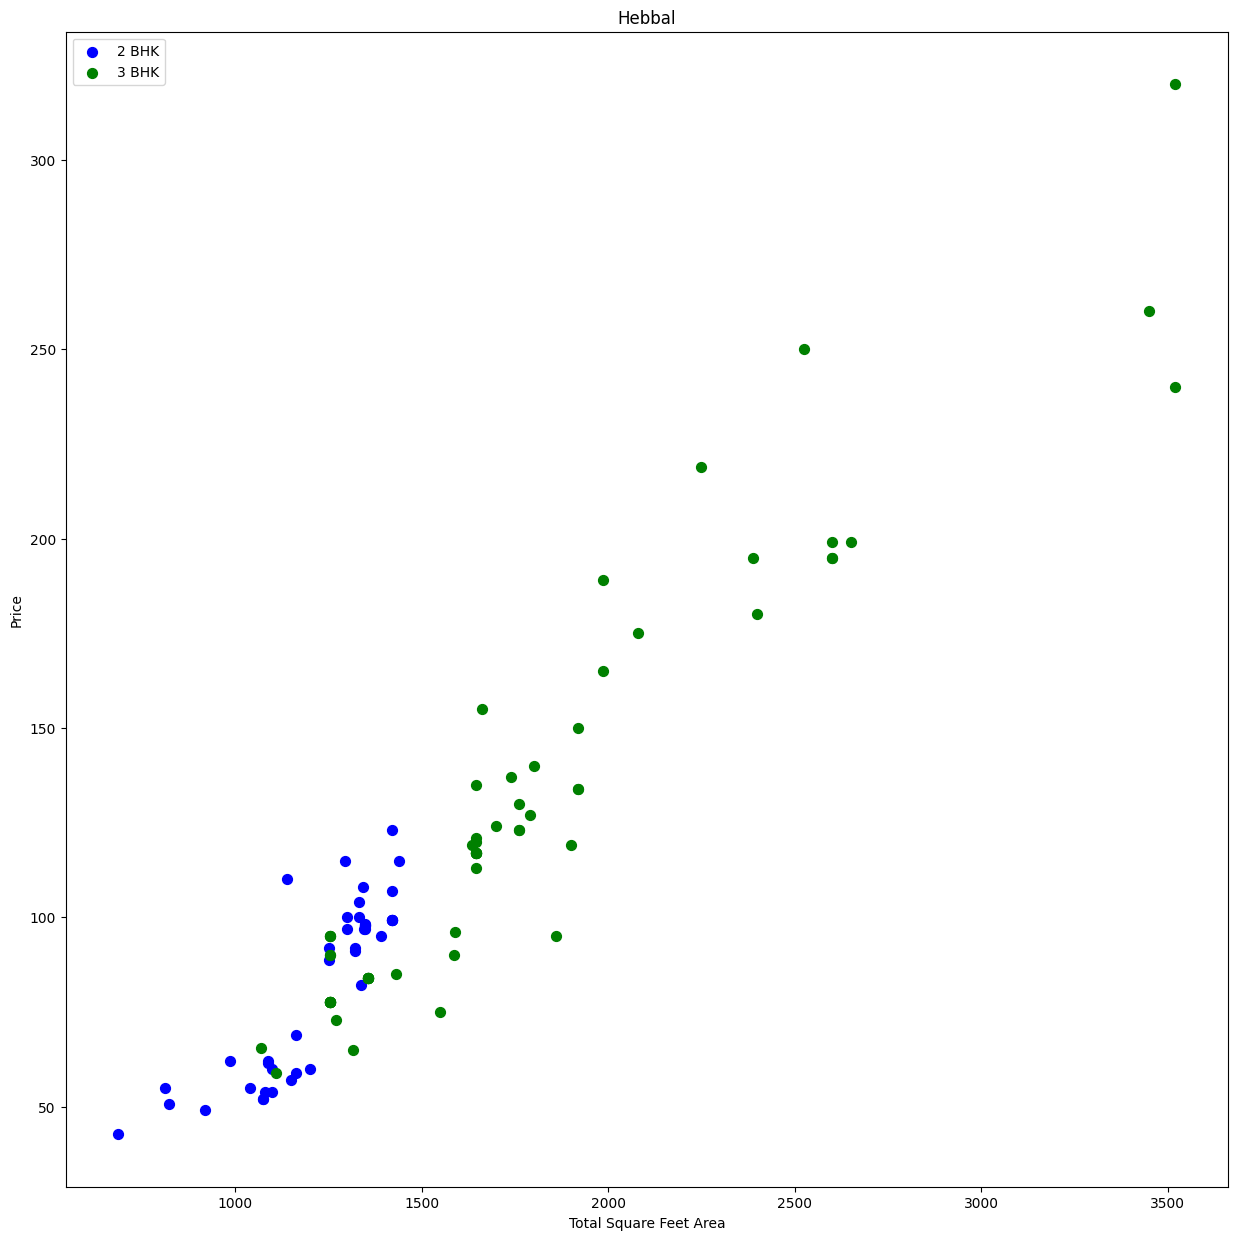

In [43]:
scatter_plot(df, "Hebbal")

**Now we can remove those 2 BHK apartments whose price_per_sqft is less than mean price_per_sqft of 1 BHK apartment**

In [44]:
def  remove_bhk_outliers(df):
    exclude_indices = np.array([])
    for location, location_df in df.groupby('location'):
        bhk_stats = {}
        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'mean' : np.mean(bhk_df.price_per_sqft),
                'std' : np.std(bhk_df.price_per_sqft),
                'count' : bhk_df.shape[0]
            }
        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk-1)
            if stats and stats['count'] > 5:
                exclude_indices = np.append(exclude_indices, bhk_df[bhk_df.price_per_sqft < (stats['mean'])].index.values)
    return df.drop(exclude_indices, axis = 'index')             

df = remove_bhk_outliers(df)
df.shape

(7317, 8)

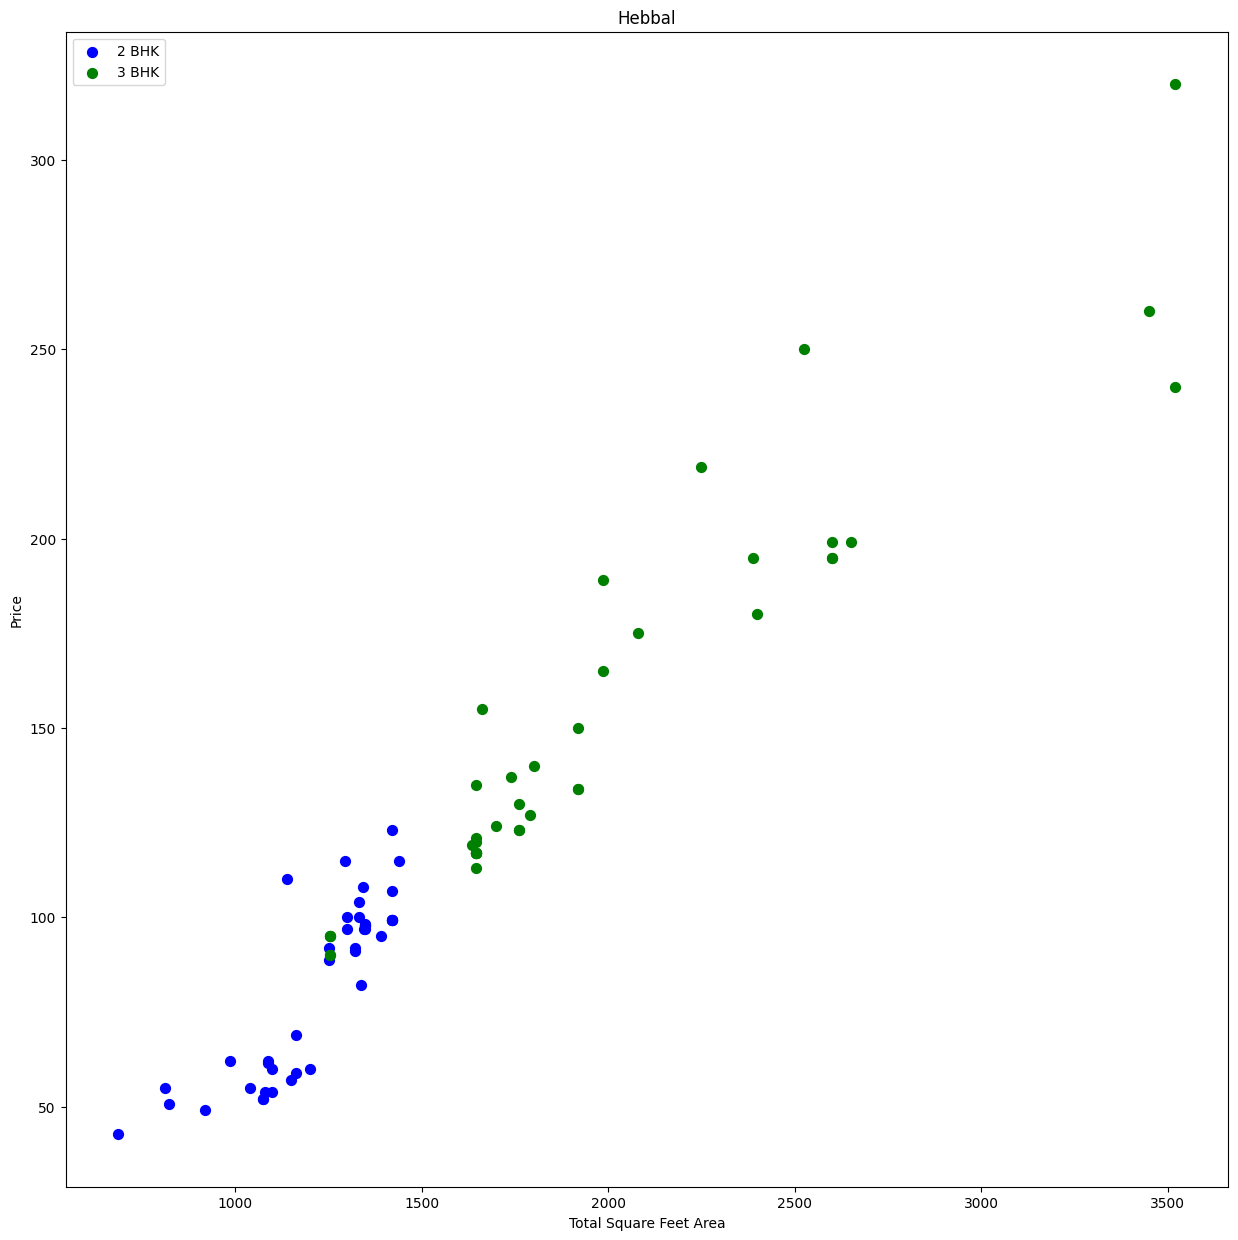

In [45]:
scatter_plot(df, "Hebbal")

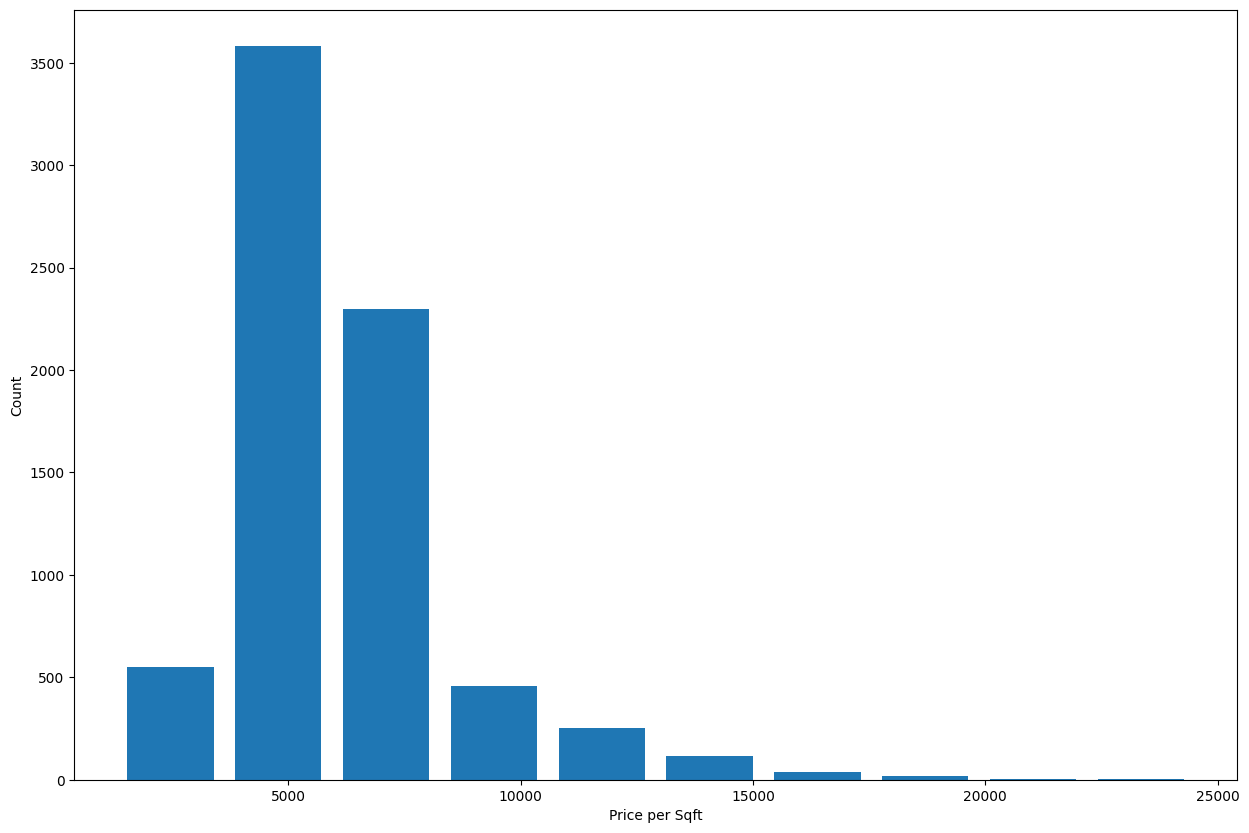

In [46]:
plt.figure(figsize = (15, 10))
plt.hist(x = 'price_per_sqft', data=df, rwidth = 0.8)
plt.xlabel('Price per Sqft')
plt.ylabel('Count')
plt.show()

### Outlier Removal for Bathrooms

In [47]:
df.bath.unique()

array([ 4.,  3.,  2.,  5.,  8.,  1.,  6.,  7.,  9., 12., 16., 13.])

In [48]:
df[df.bath > 10]

,location,size,total_sqft,bath,price,is_ready,bhk,price_per_sqft
5277,Neeladri Nagar,10 BHK,4000.0,12.0,160.0,1,10,4000.000000
5926,Other,10 BHK,12000.0,12.0,525.0,1,10,4375.000000
6015,Other,16 BHK,10000.0,16.0,550.0,1,16,5500.000000
6749,Other,11 BHK,6000.0,12.0,150.0,1,11,2500.000000
7080,Other,13 BHK,5425.0,13.0,275.0,1,13,5069.124424


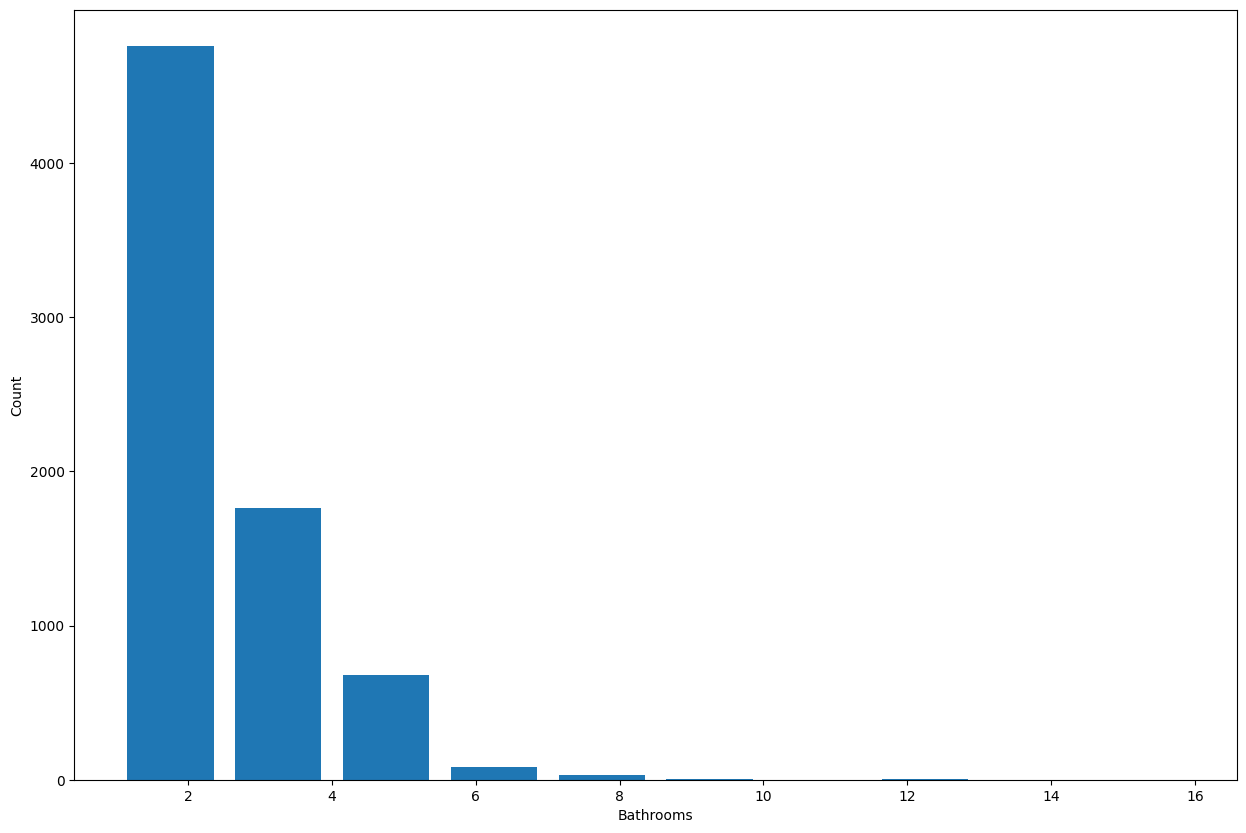

In [49]:
plt.figure(figsize = (15, 10))
plt.hist(x = 'bath', data=df, rwidth = 0.8)
plt.xlabel('Bathrooms')
plt.ylabel('Count')
plt.show()

- It is unusual to have more than 2 bathrooms for a 2bhk.
- Assuming that it is okay in some circumstances where it is 2bhk + 2.
- Bathrooms > bedrooms + 2 => These are outliers

In [50]:
df[df.bath>df.bhk+2]

,location,size,total_sqft,bath,price,is_ready,bhk,price_per_sqft
1626,Chikkabanavar,4 Bedroom,2460.0,7.0,80.0,1,4,3252.032520
5238,Nagasandra,4 Bedroom,7000.0,8.0,450.0,1,4,6428.571429
5851,Other,6 BHK,11338.0,9.0,1000.0,1,6,8819.897689
9017,Thanisandra,3 BHK,1806.0,6.0,116.0,1,3,6423.034330


In [51]:
df = df[df.bath<df.bhk+2]
df.shape

(7239, 8)

In [52]:
df = df.drop(['size','price_per_sqft'], axis='columns')
df.head()

,location,total_sqft,bath,price,is_ready,bhk
0,1st Block Jayanagar,2850.0,4.0,428.0,0,4
1,1st Block Jayanagar,1630.0,3.0,194.0,0,3
2,1st Block Jayanagar,1875.0,2.0,235.0,1,3
3,1st Block Jayanagar,1200.0,2.0,130.0,0,3
4,1st Block Jayanagar,1235.0,2.0,148.0,0,2


#### Use One Hot Encoding For Location

In [53]:
# dummies = pd.get_dummies(df.location)
# dummies.head()
# dummies.astype(int)
# df = pd.concat([df, dummies.drop('Other', axis = 'columns')], axis = 'columns')
# df.head()
# df = df.drop('location', axis = 'columns')
# df.head()

In [54]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis='columns')
y = df.price

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=10
)


### _Target Encoding_

In [55]:
location_mean = y_train.groupby(X_train['location']).mean()


combo_mean = y_train.groupby(
    [X_train['location'], X_train['bhk']]
).mean()


overall_mean = y_train.mean()

print("Location means (top 5):")
print(location_mean.head())
print("\nCombo means (top 10):")
print(combo_mean.head(10))


Location means (top 5):
location
1st Block Jayanagar          294.666667
1st Phase JP Nagar           122.366667
2nd Phase Judicial Layout     43.900000
2nd Stage Nagarbhavi         218.750000
5th Block Hbr Layout          76.000000
Name: price, dtype: float64

Combo means (top 10):
location                   bhk
1st Block Jayanagar        3      186.333333
                           4      403.000000
1st Phase JP Nagar         1       50.000000
                           2       99.062500
                           3      181.600000
                           5       85.000000
2nd Phase Judicial Layout  2       40.500000
                           3       49.000000
2nd Stage Nagarbhavi       4      218.750000
5th Block Hbr Layout       2       52.000000
Name: price, dtype: float64


In [56]:
def get_encoded_value(loc, bhk):
    # Pehle combo try karo (best)
    if (loc, bhk) in combo_mean:
        return combo_mean[(loc, bhk)]
    
    elif loc in location_mean:
        return location_mean[loc]
    
    else:
        return overall_mean

In [57]:
X_train['location'] = [
    get_encoded_value(loc, bhk)
    for loc, bhk in zip(X_train['location'], X_train['bhk'])
]

X_test['location'] = [
    get_encoded_value(loc, bhk)
    for loc, bhk in zip(X_test['location'], X_test['bhk'])
]

print("Columns:", X_train.shape[1])
print(X_train.head())

Columns: 5
       location  total_sqft  bath  is_ready  bhk
9381  54.884615      1200.0   2.0         1    2
8845  62.428571      1152.0   2.0         1    2
6838  42.275721       600.0   1.0         1    1
3317  53.600781      1210.0   2.0         1    2
229   49.601000      1510.0   2.0         1    2


In [58]:
df.shape


(7239, 6)

In [59]:
df.head()

,location,total_sqft,bath,price,is_ready,bhk
0,1st Block Jayanagar,2850.0,4.0,428.0,0,4
1,1st Block Jayanagar,1630.0,3.0,194.0,0,3
2,1st Block Jayanagar,1875.0,2.0,235.0,1,3
3,1st Block Jayanagar,1200.0,2.0,130.0,0,3
4,1st Block Jayanagar,1235.0,2.0,148.0,0,2


### Building a Machine Learning Model

In [60]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [61]:
y_pred = lr_model.predict(X_test)


r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1-r2)*(n-1)) / (n-p-1)
print("Adjusted R2 Score:", adjusted_r2)


R2 Score: 0.8405394900076433
Adjusted R2 Score: 0.8399865756179333


In [62]:
y_pred

array([ 54.70283086, 125.55584397,  71.82316768, ...,  56.00292942,
        84.85494117, 133.18462909])

In [63]:
y_test

10163     46.17
5578     115.00
2810      54.00
5014      81.00
3475      56.12
          ...  
7595     130.00
1342      31.48
853       65.12
9536      85.00
3097     120.00
Name: price, Length: 1448, dtype: float64

### Use K Fold cross validation to measure accuracy of our LinearRegression model

In [64]:
from sklearn.model_selection import ShuffleSplit, cross_val_score

cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
scores = cross_val_score(LinearRegression(), X_train, y_train, cv=cv)

print("Har Split Score:", scores.round(2))
print("Average R2     :", round(scores.mean(), 4))
print("Std Deviation  :", round(scores.std(), 4))

Har Split Score: [0.84 0.85 0.85 0.89 0.86]
Average R2     : 0.8565
Std Deviation  : 0.0174


In [93]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge

from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
pd.set_option('display.max_colwidth', None)

def find_best_model_using_gridsearchcv(X, y):
    algos = {
        'linear_regression': {
            'model': LinearRegression(),
            'params': {}
        },
        'lasso': {
            'model': Lasso(),
            'params': {
                'alpha': [0.0001, 0.001, 0.01, 0.1, 1]
            }
        },
        'ridge': {
            'model': Ridge(),
            'params': {
                'alpha': [0.0001, 0.001, 0.01, 0.1, 1]
            }
        },
        'elastic_net': {
            'model': ElasticNet(),
            'params': {
                'alpha': [0.0001, 0.001, 0.01, 0.1],
                'l1_ratio': [0.2, 0.5, 0.8]
            }
        },
        'decision_tree': {
            'model': DecisionTreeRegressor(),
            'params': {
                'criterion': ['squared_error', 'friedman_mse', 'absolute_error'],
                'splitter': ['best', 'random'],
                'max_depth' : [3, 5, 7, 10, 12, 15],
                'max_features': ['auto' ,'sqrt' ,'log2' ]
            }
        },
        'random_forest': {
            'model': RandomForestRegressor(),
            'params': {
                'n_estimators': [10, 50, 100],
                'max_depth': [None, 5, 10]
            }
        },
        'gradient_boosting': {
            'model': GradientBoostingRegressor(),
            'params': {
                'n_estimators': [100, 200],
                'learning_rate': [0.05, 0.1]
            }
        },
        'xgboost': {
        'model': XGBRegressor(),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.05, 0.1],
            'max_depth': [3, 5, 7, 12]
        }
    }
    }

    scores = []
    cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)

    for algo_name, config in algos.items():
        gs = GridSearchCV(config['model'], config['params'],
                         cv=cv, return_train_score=False , n_jobs = -1)
        gs.fit(X, y)
        scores.append({
            'model': algo_name,
            'best_score': gs.best_score_,
            'best_params': gs.best_params_
        })

    return pd.DataFrame(scores,
                       columns=['model', 'best_score', 'best_params'])
find_best_model_using_gridsearchcv(X_train, y_train)



,model,best_score,best_params
0,linear_regression,0.856548,{}
1,lasso,0.856722,{'alpha': 1}
2,ridge,0.856549,{'alpha': 1}
3,elastic_net,0.856566,"{'alpha': 0.01, 'l1_ratio': 0.5}"
4,decision_tree,0.846657,"{'criterion': 'squared_error', 'max_depth': 15, 'max_features': 'log2', 'splitter': 'best'}"
5,random_forest,0.883390,"{'max_depth': 10, 'n_estimators': 50}"
6,gradient_boosting,0.881023,"{'learning_rate': 0.1, 'n_estimators': 200}"
7,xgboost,0.872404,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}"


In [78]:
print(X_train.columns.tolist())
print(X_train.head(3))

['location', 'total_sqft', 'bath', 'is_ready', 'bhk']
       location  total_sqft  bath  is_ready  bhk
9381  54.884615      1200.0   2.0         1    2
8845  62.428571      1152.0   2.0         1    2
6838  42.275721       600.0   1.0         1    1


In [89]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

final_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=10,
    random_state=42
)
final_model.fit(X_train, y_train)



def predict_price(location, sqft, bath, is_ready, bhk):
    input_data = pd.DataFrame([[
        location_mean.get(location, overall_mean),
        sqft,
        bath,
        is_ready,
        bhk
    ]], columns=X_train.columns)
    
    return round(final_model.predict(input_data)[0], 2)


print(predict_price("Indira Nagar", 1000, 2, 1, 2))
print(predict_price("Kasturi Nagar", 1925, 3, 1, 3))
print(predict_price("Indira Nagar", 2500, 5, 1, 5))
print(predict_price("Kothanur", 1200, 2, 1, 2))
print(predict_price("Chikka Tirupathi", 2600, 5, 1, 4))

158.82
116.37
277.21
84.42
121.44
